# Serial Hybrid Digital Twin — Methanol Reactor
# In this model physics runs first and ML only corrects the leftover error. The final prediction is physics + residual

**Approach:** physics → residual (ML)→ interactive digital twin.


| Role | Variables |
|------|-----------|
| **Inputs (3)** | Inlet T (°C), Inlet P (bar_g), Methanol flow (kgmole/h) |
| **Outputs (8)** | Temp_0.2m … Temp_1m (°C), P_out (bar_g), Q (kW), Conversion (%) |


## 1. Imports

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from scipy.integrate import solve_ivp
from scipy.optimize import minimize_scalar

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.multioutput import MultiOutputRegressor

DATA_FILE = Path("DATA.xlsx")

MEASUREMENT_POSITIONS_M = np.array([0.2, 0.4, 0.6, 0.8, 1.0])

P_ATM_BAR = 1.01325

INPUT_COLS = ["T_in_C", "P_in_bar_g", "F_in_kgmole_h"]

OUTPUT_COLS = [
    "T_0.2m_C", "T_0.4m_C", "T_0.6m_C", "T_0.8m_C", "T_1m_C",
    "P_out_bar_g", "Q_total_kW", "X_overall_pct",
]

print("Libraries loaded.")
print("Data file:", DATA_FILE.resolve())

Libraries loaded.
Data file: C:\Users\krish\JBS Tech\Methanol Reforming\change\DATA.xlsx


## 2. Load Excel data (`DATA.xlsx`)

In [4]:
def load_excel(path: Path) -> pd.DataFrame:
    # Load sheet with two header rows
    raw = pd.read_excel(path, sheet_name="Data", header=[0, 1])
    # Join the two header rows into single column names
    raw.columns = [
        f"{name} ({unit})" if pd.notna(unit) and str(unit).strip() else str(name)
        for name, unit in raw.columns
    ]
    # Rename columns to simplified names
    data = raw.rename(
        columns={
            "Inlet Temperature (C)": "T_in_C",
            "Inlet Pressure (bar_g)": "P_in_bar_g",
            "Inlet molar flow rate (kgmole/h)": "F_in_kgmole_h",
            "Temp_0.2m (C)": "T_0.2m_C",
            "Temp_0.4m (C)": "T_0.4m_C",
            "Temp_0.6m (C)": "T_0.6m_C",
            "Temp_0.8m (C)": "T_0.8m_C",
            "Temp_1m (C)": "T_1m_C",
            "Outlet Pressure (bar_g)": "P_out_bar_g",
            "Total heat input (KW)": "Q_total_kW",
            "Overall Conversion (%)": "X_overall_pct",
        }
    )
    # Check for negatives (except for Q which can be negative)
    n_raw = len(data)
    neg_report = {
        "X_overall_pct": int((data["X_overall_pct"] < 0).sum()),
        "P_out_bar_g": int((data["P_out_bar_g"] < 0).sum()),
        "P_in_bar_g": int((data["P_in_bar_g"] < 0).sum()),
        "F_in_kgmole_h": int((data["F_in_kgmole_h"] < 0).sum()),
        "T_in_C": int((data["T_in_C"] < 0).sum()),
        "axial T": int((data[["T_0.2m_C", "T_0.4m_C", "T_0.6m_C", "T_0.8m_C", "T_1m_C"]] < 0).any(axis=1).sum()),
        "Q_total_kW (kept)": int((data["Q_total_kW"] < 0).sum()),
    }
    print("Negative-value scan before cleaning:")
    for name, count in neg_report.items():
        print(f"  {name}: {count} rows")
    # Define valid/clean data, removing cases with unphysical values or NaN
    ok = (
        data["X_overall_pct"].between(0, 5)
        & data["P_out_bar_g"].ge(0)
        & data["P_in_bar_g"].ge(0)
        & data["F_in_kgmole_h"].gt(0)
        & data["T_in_C"].ge(0)
        & data[["T_0.2m_C", "T_0.4m_C", "T_0.6m_C", "T_0.8m_C", "T_1m_C"]].ge(0).all(axis=1)
        & data["Q_total_kW"].between(-50, 50)
        & data[INPUT_COLS].notna().all(axis=1)
        & data[OUTPUT_COLS].notna().all(axis=1)
    )
    # Keep only the good rows
    cleaned = data.loc[ok].reset_index(drop=True)
    print(f"Rows: {n_raw} raw → {len(cleaned)} after removing negatives / bad cases")
    return cleaned

# Load the cleaned dataframe
df = load_excel(DATA_FILE)
print(f"Valid rows loaded: {len(df)}")
print("Remaining negatives (should be Q only):")
print((df[INPUT_COLS + OUTPUT_COLS] < 0).sum().to_string())
display(df[INPUT_COLS + OUTPUT_COLS].head())

Negative-value scan before cleaning:
  X_overall_pct: 67 rows
  P_out_bar_g: 124 rows
  P_in_bar_g: 0 rows
  F_in_kgmole_h: 0 rows
  T_in_C: 0 rows
  axial T: 0 rows
  Q_total_kW (kept): 1122 rows
Rows: 1122 raw → 997 after removing negatives / bad cases
Valid rows loaded: 997
Remaining negatives (should be Q only):
T_in_C             0
P_in_bar_g         0
F_in_kgmole_h      0
T_0.2m_C           0
T_0.4m_C           0
T_0.6m_C           0
T_0.8m_C           0
T_1m_C             0
P_out_bar_g        0
Q_total_kW       997
X_overall_pct      0


,T_in_C,P_in_bar_g,F_in_kgmole_h,T_0.2m_C,T_0.4m_C,T_0.6m_C,T_0.8m_C,T_1m_C,P_out_bar_g,Q_total_kW,X_overall_pct
0,200,0.4,0.10,113.6,125.2,135.9,145.5,154.1,0.3691,-0.7511,0.308629
1,200,0.4,0.35,115.0,114.7,118.4,122.7,126.8,0.2898,-0.8192,0.131113
2,200,0.4,0.60,120.2,116.4,117.7,120.1,122.8,0.1530,-0.9237,0.102860
3,200,0.8,0.10,113.4,125.0,135.8,145.4,154.1,0.7760,-0.7527,0.309011
4,200,0.8,0.35,114.7,114.4,118.2,122.5,126.7,0.7156,-0.8223,0.131407


## 3. Fixed reactor physics parameters

Same geometry / LHHW kinetics as the physics model.  
A global rate multiplier `ETA` will be calibrated next so conversion is close to Excel.

In [5]:
R = 8.314462618          # Universal gas constant [J/(mol·K)]
D = 0.1                  # Reactor diameter [m]
L = 1.0                  # Reactor length [m]
h_heat = 115.0           # Heat transfer coefficient [W/m²·°C]
T_heat_C = 275.0         # Heater temperature [°C]
epsilon = 0.33           # Bed void fraction
dp = 1.0e-3              # Particle diameter [m]
Ac = np.pi * D**2 / 4    # Reactor cross-sectional area [m²]
perimeter = np.pi * D    # Reactor internal perimeter [m]

MW_CH3OH = 32.04e-3      # Methanol molecular weight [kg/mol]
MW_CO = 28.01e-3         # CO molecular weight [kg/mol]
MW_H2 = 2.016e-3         # H2 molecular weight [kg/mol]

Cp_CH3OH = 43.0          # Methanol heat capacity [J/(mol·K)]
Cp_CO = 29.0             # CO heat capacity [J/(mol·K)]
Cp_H2 = 29.0             # H2 heat capacity [J/(mol·K)]

A_kinetic = 7.0e10       # Kinetic prefactor (LHHW model)
E_kinetic = 19120.0      # Activation energy [J/mol] (LHHW)
A_CO = 1.0e7             # CO adsorption pre-factor
E_CO = 6036.8            # CO adsorption energy [J/mol]
delta_H = 90.5e3         # Reaction enthalpy [J/mol] (CH3OH -> CO + 2H2)

ETA = 1.0                # Rate adjustment factor

print(f"D={D} m, L={L} m, T_heat={T_heat_C} °C, delta_H={delta_H/1000:.1f} kJ/mol")

D=0.1 m, L=1.0 m, T_heat=275.0 °C, delta_H=90.5 kJ/mol


## 4. Unit conversions + physics ODE model

In [6]:
def bar_g_to_Pa(P_bar_g):
    # Convert gauge pressure (bar) to absolute pressure (Pa)
    return (P_bar_g + P_ATM_BAR) * 1.0e5

def Pa_to_bar_g(P_Pa):
    # Convert absolute pressure (Pa) to gauge pressure (bar)
    return P_Pa / 1.0e5 - P_ATM_BAR

def kgmole_h_to_mol_s(F_kgmole_h):
    # Convert flowrate from kgmole/h to mol/s
    return F_kgmole_h * 1000.0 / 3600.0

def reaction_rate(T_C, P, F_CH3OH, F_CO, F_H2, eta=None):
    # Calculate reaction rate (LHHW) in [mol/(m³·s)]
    if eta is None:
        eta = ETA
    T_abs = T_C + 273.15  # Absolute temperature [K]
    F_total = max(F_CH3OH + F_CO + F_H2, 1e-12)
    C_total = P / (R * T_abs)  # Total concentration [mol/m³]
    C_CH3OH = (F_CH3OH / F_total) * C_total
    C_CO = (F_CO / F_total) * C_total
    numerator = A_kinetic * np.exp(-E_kinetic / (R * T_abs)) * C_CH3OH
    denominator = 1.0 + A_CO * np.exp(-E_CO / (R * T_abs)) * C_CO
    return eta * numerator / denominator

def reactor_model(z, y, eta=None):
    # Compute ODE right-hand side for the reactor model
    # y = [F_CH3OH, F_CO, F_H2, T_C, P_Pa, Q_W]
    if eta is None:
        eta = ETA
    F_CH3OH = max(y[0], 1e-12)
    F_CO = max(y[1], 0.0)
    F_H2 = max(y[2], 0.0)
    T_C = y[3]
    P = max(y[4], 1.0e3)

    r = reaction_rate(T_C, P, F_CH3OH, F_CO, F_H2, eta=eta)  # reaction rate
    rpl = r * Ac  # rate per length [mol/(s·m)]

    # Reaction stoichiometry
    dF_CH3OH_dz = -rpl           # CH3OH consumed
    dF_CO_dz = rpl               # CO produced
    dF_H2_dz = 2.0 * rpl         # H2 produced

    # --- Energy balance and pressure drop calculations ---
    
    # Calculate heat transferred to/from the tube wall [W]
    q_transfer = h_heat * perimeter * (T_heat_C - T_C)  # h*A*ΔT

    # Calculate total (molar) heat capacity flow [J/K/s], prevent div by zero
    Cp_flow = max(F_CH3OH * Cp_CH3OH + F_CO * Cp_CO + F_H2 * Cp_H2, 1e-9)

    # Compute change in temperature per unit length [K/m]
    # Includes heat transferred and enthalpy of reaction
    dT_dz = (q_transfer - delta_H * rpl) / Cp_flow

    # --- Pressure drop calculations ---
    # Compute total outlet molar flow [mol/s]
    F_total = F_CH3OH + F_CO + F_H2

    # Compute total mass flow [kg/s]
    mass_flow = F_CH3OH * MW_CH3OH + F_CO * MW_CO + F_H2 * MW_H2

    # Mixture average molecular weight [kg/mol]
    MW_mix = mass_flow / max(F_total, 1e-12)

    # Calculate absolute temperature [K]
    T_abs = T_C + 273.15

    # Compute fluid density [kg/m³]: ρ = P*MW/(R*T)
    rho = P * MW_mix / (R * T_abs)

    # Calculate superficial velocity [m/s]: u = mass_flow/(ρ*A)
    velocity = mass_flow / max(rho * Ac, 1e-12)

    # Effective viscosity [Pa·s] (assumed constant here)
    mu = 2.0e-5

    # Calculate viscous pressure drop term (Ergun equation, 1st term)
    viscous = 150.0 * mu * (1.0 - epsilon) ** 2 / (epsilon ** 3 * dp ** 2) * velocity

    # Calculate inertial pressure drop term (Ergun equation, 2nd term)
    inertial = 1.75 * rho * (1.0 - epsilon) / (epsilon ** 3 * dp) * velocity ** 2

    # Compute total pressure drop per unit length [Pa/m] (negative sign for drop)
    dP_dz = -(viscous + inertial)

    # Calculate total heat flow per unit length (W/m)
    dQ_dz = q_transfer

    # Return derivatives of state variables [dF_CH3OH/dz, dF_CO/dz, dF_H2/dz, dT/dz, dP/dz, dQ/dz]
    return [dF_CH3OH_dz, dF_CO_dz, dF_H2_dz, dT_dz, dP_dz, dQ_dz]

def predict_physics(T_in_C, P_in_bar_g, F_in_kgmole_h, eta=None, n_points=80):
    # Run the physics model for one set of inputs and return outputs
    if eta is None:
        eta = ETA
    F_in = kgmole_h_to_mol_s(F_in_kgmole_h)
    P_in_Pa = bar_g_to_Pa(P_in_bar_g)
    y0 = [F_in, 0.0, 0.0, float(T_in_C), P_in_Pa, 0.0]  # initial state
    z_eval = np.linspace(0.0, L, n_points)             # axial positions

    # Solve ODEs along reactor length
    sol = solve_ivp(
        lambda z, y: reactor_model(z, y, eta=eta),
        (0.0, L),
        y0,
        t_eval=z_eval,
        method="BDF",
        rtol=1e-5,
        atol=1e-8,
    )
    if not sol.success:
        raise RuntimeError(sol.message)

    F_out = float(sol.y[0, -1])                        # Outlet CH3OH flow
    T_profile = sol.y[3]                               # Temperature profile
    T_axial = np.interp(MEASUREMENT_POSITIONS_M, sol.t, T_profile)
    X_pct = (F_in - F_out) / F_in * 100.0             # Conversion %

    # Return all requested outputs
    return {
        "T_0.2m_C": float(T_axial[0]),
        "T_0.4m_C": float(T_axial[1]),
        "T_0.6m_C": float(T_axial[2]),
        "T_0.8m_C": float(T_axial[3]),
        "T_1m_C": float(T_axial[4]),
        "P_out_bar_g": float(Pa_to_bar_g(sol.y[4, -1])),
        "Q_total_kW": float(sol.y[5, -1] / 1000.0),
        "X_overall_pct": float(X_pct),
        "z_m": sol.t,
        "T_profile_C": T_profile,
    }

def physics_vector(T_in_C, P_in_bar_g, F_in_kgmole_h, eta=None):
    # Return the 8 main physics model outputs as a numpy vector
    p = predict_physics(T_in_C, P_in_bar_g, F_in_kgmole_h, eta=eta)
    return np.array([p[c] for c in OUTPUT_COLS], dtype=float)

print("Physics model functions ready.")

Physics model functions ready.


## 5. Train / test split

80% train for η + residual ML, 20% held out for validation.

In [7]:
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f"Train rows: {len(train_df)}")
print(f"Test rows : {len(test_df)}")

Train rows: 797
Test rows : 200


## 6. Calibrate the physics model to better match the data

The original physics equations by themselves tend to overestimate how much reaction happens (conversion).
To fix this, we adjust a single multiplier parameter, `η` (eta), so that the physics model's conversion predictions are closer to the real data from Excel.
We use only the training data for this adjustment, and this helps make sure the physics model is reasonably accurate before using machine learning to improve any remaining errors.

In [8]:
def calibrate_eta(df_train, n_cases=40):
    # Choose a small random subset of training data to speed up calibration
    sample = df_train.sample(n=min(n_cases, len(df_train)), random_state=42)

    # Define an objective function for optimization: takes log10(eta) and returns the average squared error
    def objective(log_eta):
        eta = float(10 ** log_eta)
        errs = []
        for _, row in sample.iterrows():
            try:
                # Run the physics model for this row, with eta
                y = physics_vector(row["T_in_C"], row["P_in_bar_g"], row["F_in_kgmole_h"], eta=eta)
                # Compare the predicted and actual conversion, store the squared error
                errs.append((y[-1] - row["X_overall_pct"]) ** 2)
                 #?? how come y[-1] is predicted overall conversion.
                 # Y variable contains output from the physics_vector and y[-1] means last row of the output column 
                 # which is "X_overall_pct"
            except Exception:
                # If the physics model fails, treat that row as a big error
                errs.append(1.0e6)
        # Return the mean squared error for this value of eta
        return float(np.mean(errs))

    print("Calibrating η (this may take ~1 minute)...")
    # Minimize the objective over log10(eta) within the given bounds
    result = minimize_scalar(
        objective, bounds=(-10.0, -4.0), method="bounded", options={"xatol": 0.05}
    )
    # Return the best eta (not log) and the minimum error found
    return float(10 ** result.x), float(result.fun)

# Run the calibration function and print the results
ETA, eta_obj = calibrate_eta(train_df, n_cases=40)
print(f"Calibrated ETA = {ETA:.6e}  (conversion MSE on sample = {eta_obj:.4f})")

Calibrating η (this may take ~1 minute)...
Calibrated ETA = 1.001097e-07  (conversion MSE on sample = 0.0024)


## 7. Run calibrated physics on all train / test rows

Builds `y_phys` for the residual stage (~2 minutes).

In [9]:
def run_physics_matrix(data, eta, label="set"):
    # Run the physics model for every row in the data
    rows = []
    for i, row in data.iterrows():
        try:
            # Get the physics model prediction for this row
            rows.append(
                physics_vector(row["T_in_C"], row["P_in_bar_g"], row["F_in_kgmole_h"], eta=eta)
            )
        except Exception:
            # If the model fails, use nan values
            rows.append(np.full(len(OUTPUT_COLS), np.nan))
        if (len(rows) % 100) == 0:
            # Print progress for every 100 rows
            print(f"  {label}: {len(rows)}/{len(data)}")
    # Stack all physics outputs into a matrix
    return np.vstack(rows)

# Run physics model on training data
print("Physics on train...")
Y_phys_train = run_physics_matrix(train_df, ETA, label="train")
# Run physics model on test data
print("Physics on test...")
Y_phys_test = run_physics_matrix(test_df, ETA, label="test")

# Convert input and output columns to numpy arrays
U_train = train_df[INPUT_COLS].to_numpy(dtype=float)
U_test = test_df[INPUT_COLS].to_numpy(dtype=float)
Y_excel_train = train_df[OUTPUT_COLS].to_numpy(dtype=float)
Y_excel_test = test_df[OUTPUT_COLS].to_numpy(dtype=float)

# Check which rows have all finite (valid) physics outputs
ok_train = np.isfinite(Y_phys_train).all(axis=1)
ok_test = np.isfinite(Y_phys_test).all(axis=1)

# Filter out rows with invalid physics output
U_train, Y_phys_train, Y_excel_train = (
    U_train[ok_train], Y_phys_train[ok_train], Y_excel_train[ok_train]
)
U_test, Y_phys_test, Y_excel_test = (
    U_test[ok_test], Y_phys_test[ok_test], Y_excel_test[ok_test]
)

# Print how many valid rows remain in train and test sets
print(f"Finite physics — train {ok_train.sum()}, test {ok_test.sum()}")

Physics on train...
  train: 100/797
  train: 200/797
  train: 300/797
  train: 400/797
  train: 500/797
  train: 600/797
  train: 700/797
Physics on test...
  test: 100/200
  test: 200/200
Finite physics — train 797, test 200


## 8. Train residual ML (forward serial)

```text
Features X = [T_in, P_in, F_in, y_phys(8)]
Target   e = y_excel − y_phys
Hybrid   ŷ = y_phys + ML(X)
```

In [10]:
def build_features(U, Y_phys):
    # Combine input variables and physics model outputs as features
    return np.hstack([U, Y_phys])

def clip_outputs(out, P_in_bar_g):
    # Make sure predicted temperatures are within [0, 800] °C
    out[0:5] = np.clip(out[0:5], 0.0, 800.0)
    # Keep predicted outlet pressure less than inlet pressure
    out[5] = min(float(out[5]), float(P_in_bar_g) - 1e-6)
    # Conversion percentage should be between 0 and 100
    out[7] = np.clip(out[7], 0.0, 100.0)
    return out

# Build training features by stacking input and physics output columns
X_train = build_features(U_train, Y_phys_train)

# Calculate residuals (Excel - Physics) for training targets, shape (n_samples, n_outputs)
E_train = Y_excel_train - Y_phys_train

# Initialize the machine learning model for the residuals (difference between Excel and physics outputs)
residual_model = HistGradientBoostingRegressor(
    max_depth=6,
    learning_rate=0.08,
    max_iter=250,
    l2_regularization=0.1,
    random_state=42,
)

# Fit the model on training data for each output dimension separately to avoid the shape error
# Train one model per each output column (multi-output regression workaround)
from sklearn.multioutput import MultiOutputRegressor
multi_residual_model = MultiOutputRegressor(residual_model)
multi_residual_model.fit(X_train, E_train)
print("Residual ML trained.")

# Predict on test set
X_test = build_features(U_test, Y_phys_test)
E_hat_test = multi_residual_model.predict(X_test)
Y_hat_test = np.copy(Y_phys_test) + E_hat_test  # Add residuals back to physics outputs

# Enforce physical limits on all hybrid predictions
for i in range(Y_hat_test.shape[0]):
    Y_hat_test[i] = clip_outputs(Y_hat_test[i], P_in_bar_g=U_test[i, 1])
print("Test predictions ready.")

Residual ML trained.
Test predictions ready.


## 9. Validate hybrid twin vs Excel (test set)

,Output,MAE physics,MAE hybrid,R2 hybrid
0,T_0.2m_C,152.4008,0.3418,0.9995
1,T_0.4m_C,146.0001,0.3497,0.9985
2,T_0.6m_C,139.7063,0.2713,0.9988
3,T_0.8m_C,134.5783,0.1980,0.9995
4,T_1m_C,130.3583,0.1398,0.9997
5,P_out_bar_g,0.0867,0.0346,0.9903
6,Q_total_kW,0.8748,0.0148,0.9616
7,X_overall_pct,0.0503,0.0007,0.9999


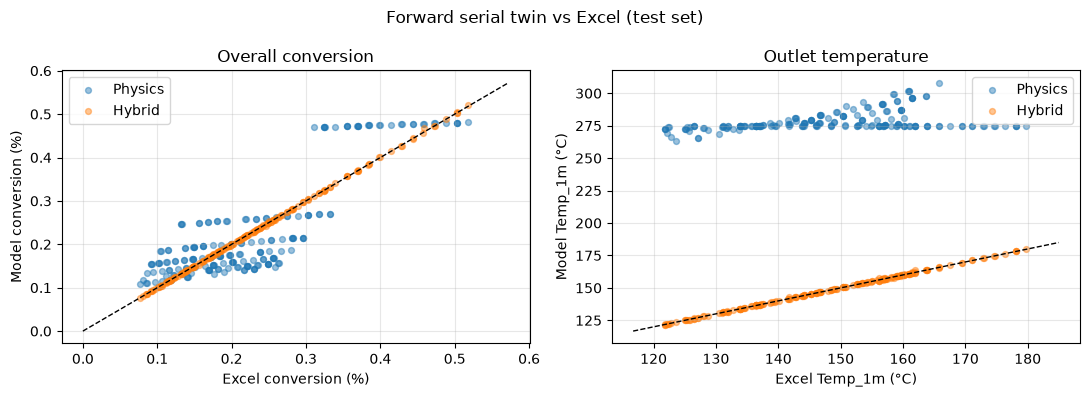

In [11]:
# Calculate and display mean absolute error (MAE) and R2 for each output variable
rows = []
for i, col in enumerate(OUTPUT_COLS):
    rows.append({
        "Output": col,
        "MAE physics": mean_absolute_error(Y_excel_test[:, i], Y_phys_test[:, i]),
        "MAE hybrid": mean_absolute_error(Y_excel_test[:, i], Y_hat_test[:, i]),
        "R2 hybrid": r2_score(Y_excel_test[:, i], Y_hat_test[:, i]),
    })

metrics = pd.DataFrame(rows)
display(metrics.round(4))

# Make side-by-side plots for: (1) conversion parity, and (2) outlet temperature parity
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Plot model vs Excel for conversion percentage (X_overall_pct)
axes[0].scatter(Y_excel_test[:, 7], Y_phys_test[:, 7], alpha=0.45, s=18, label="Physics")
axes[0].scatter(Y_excel_test[:, 7], Y_hat_test[:, 7], alpha=0.45, s=18, label="Hybrid")
lim = max(Y_excel_test[:, 7].max(), Y_hat_test[:, 7].max(), 1e-6) * 1.1
axes[0].plot([0, lim], [0, lim], "k--", lw=1)  # reference line
axes[0].set_xlabel("Excel conversion (%)")
axes[0].set_ylabel("Model conversion (%)")
axes[0].set_title("Overall conversion")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot model vs Excel for outlet temperature
axes[1].scatter(Y_excel_test[:, 4], Y_phys_test[:, 4], alpha=0.45, s=18, label="Physics")
axes[1].scatter(Y_excel_test[:, 4], Y_hat_test[:, 4], alpha=0.45, s=18, label="Hybrid")
t0 = min(Y_excel_test[:, 4].min(), Y_hat_test[:, 4].min()) - 5
t1 = max(Y_excel_test[:, 4].max(), Y_hat_test[:, 4].max()) + 5
axes[1].plot([t0, t1], [t0, t1], "k--", lw=1)  # reference line
axes[1].set_xlabel("Excel Temp_1m (°C)")
axes[1].set_ylabel("Model Temp_1m (°C)")
axes[1].set_title("Outlet temperature")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Add title and adjust layout
fig.suptitle("Forward serial twin vs Excel (test set)")
fig.tight_layout()
plt.show()

## 10. Digital twin prediction function

`predict_outputs(T_in, P_in, F_in)` runs calibrated physics first, then adds the residual ML correction:

```text
ŷ = y_phys(η) + ML(u, y_phys)
```

In [75]:
def predict_outputs(T_in_C, P_in_bar_g, F_in_kgmole_h):
    """
    Digital twin: 3 plant inputs → 8 hybrid outputs.

    Steps:
      1) Run calibrated physics → y_phys
      2) Residual ML predicts correction e
      3) Return ŷ = y_phys + e (with physical clipping)
    """
    # Get physics-based prediction
    phys = predict_physics(T_in_C, P_in_bar_g, F_in_kgmole_h, eta=ETA)
    y_phys = np.array([phys[c] for c in OUTPUT_COLS], dtype=float)

    # Get ML correction for residual error
    u = np.array([[T_in_C, P_in_bar_g, F_in_kgmole_h]], dtype=float)
    e = multi_residual_model.predict(build_features(u, y_phys.reshape(1, -1)))[0]
    # Add physics result and ML correction; apply output limits
    y_hat = clip_outputs(y_phys + e, P_in_bar_g=P_in_bar_g)

    # Prepare output dictionary for user: final, physics, and correction
    out = {c: float(y_hat[i]) for i, c in enumerate(OUTPUT_COLS)}
    out["y_phys"] = {c: float(y_phys[i]) for i, c in enumerate(OUTPUT_COLS)}
    out["residual"] = {c: float(e[i]) for i, c in enumerate(OUTPUT_COLS)}
    # Include extra details for debugging/analysis
    out["z_m"] = phys["z_m"]
    out["T_profile_C"] = phys["T_profile_C"]
    return out

# --- Quick demonstration with first row from Excel input ---
demo = df.iloc[0]
# Calculate prediction for the demo row
demo_pred = predict_outputs(demo["T_in_C"], demo["P_in_bar_g"], demo["F_in_kgmole_h"])

# Build quick comparison DataFrame for Excel, physics result, and hybrid result
smoke = pd.DataFrame({
    "Output": OUTPUT_COLS,
    "Excel": [demo[c] for c in OUTPUT_COLS],
    "Physics": [demo_pred["y_phys"][c] for c in OUTPUT_COLS],
    "Hybrid twin": [demo_pred[c] for c in OUTPUT_COLS],
})
# Calculate and display absolute error
smoke["Abs error"] = (smoke["Hybrid twin"] - smoke["Excel"]).abs()
print("Smoke test — first DATA.xlsx row:")
display(smoke.round(4))

Smoke test — first DATA.xlsx row:


,Output,Excel,Physics,Hybrid twin,Abs error
0,T_0.2m_C,113.6000,274.3918,114.0052,0.4052
1,T_0.4m_C,125.2000,274.7219,124.8910,0.3090
2,T_0.6m_C,135.9000,274.7787,136.0500,0.1500
3,T_0.8m_C,145.5000,274.8106,145.6863,0.1863
4,T_1m_C,154.1000,274.8317,154.2152,0.1152
5,P_out_bar_g,0.3691,0.3522,0.3719,0.0028
6,Q_total_kW,-0.7511,0.1013,-0.7589,0.0078
7,X_overall_pct,0.3086,0.4697,0.3096,0.0009



  METHANOL REACTOR — FORWARD SERIAL DIGITAL TWIN
  ŷ = y_phys(η) + ML residual
  Using calibrated η = 1.001097e-07
  Press Enter to accept the default value shown in [brackets].
  Type q at any prompt to stop.


------------------------------------------------------------
INPUTS
  Inlet Temperature     : 200.00 °C
  Inlet Pressure        : 0.4000 bar_g
  Methanol flow         : 0.1000 kgmole/h

HYBRID TWIN OUTPUTS
  Temp_0.2m             : 114.01 °C
  Temp_0.4m             : 124.89 °C
  Temp_0.6m             : 136.05 °C
  Temp_0.8m             : 145.69 °C
  Temp_1m (outlet)      : 154.22 °C
  Outlet Pressure       : 0.3719 bar_g
  Total heat input      : -0.7589 kW
  Overall Conversion    : 0.3096 %
------------------------------------------------------------


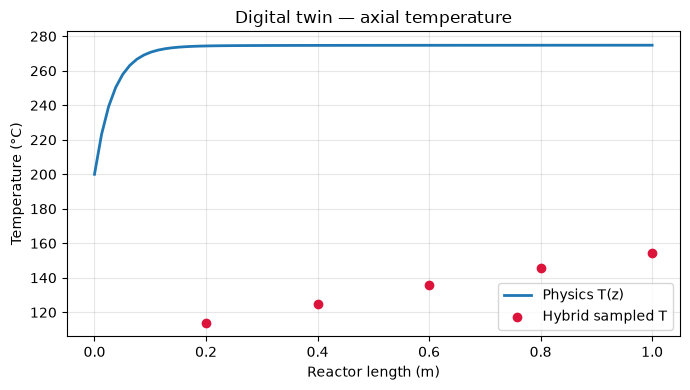

Digital twin stopped.


In [76]:
def _ask_float(prompt, default=None):
    # Prompt user for a float, with default and quit option
    hint = f" [{default}]" if default is not None else ""
    while True:
        raw = input(f"{prompt}{hint}: ").strip()
        if raw.lower() in {"q", "quit", "exit"}:
            return None  # User chose to quit
        if raw == "" and default is not None:
            return float(default)  # Use default
        try:
            return float(raw)  # User input as float
        except ValueError:
            print("  Please enter a number (or q to quit).")  # Invalid input


def run_digital_twin_interactive():
    """Main loop: get user input, show predictions."""
    print("\n" + "=" * 60)
    print("  METHANOL REACTOR — FORWARD SERIAL DIGITAL TWIN")
    print("  ŷ = y_phys(η) + ML residual")
    print("=" * 60)
    print(f"  Using calibrated η = {ETA:.6e}")
    print("  Press Enter to accept the default value shown in [brackets].")
    print("  Type q at any prompt to stop.\n")

    while True:
        # Get user inputs with defaults
        T_in_C = _ask_float("Inlet temperature [°C]", default=200.0)
        if T_in_C is None:
            print("Digital twin stopped.")
            break

        P_in_bar_g = _ask_float("Inlet pressure [bar_g]", default=0.4)
        if P_in_bar_g is None:
            print("Digital twin stopped.")
            break

        F_in_kgmole_h = _ask_float("Methanol molar flow [kgmole/h]", default=0.1)
        if F_in_kgmole_h is None:
            print("Digital twin stopped.")
            break

        if F_in_kgmole_h <= 0:
            print("  Flow must be > 0. Try again.\n")  # Validate flow
            continue

        try:
            pred = predict_outputs(T_in_C, P_in_bar_g, F_in_kgmole_h)  # Run model
        except Exception as exc:
            print(f"  Prediction failed: {exc}\n")  # Handle errors
            continue

        # Print results
        print("\n" + "-" * 60)
        print("INPUTS")
        print(f"  Inlet Temperature     : {T_in_C:.2f} °C")
        print(f"  Inlet Pressure        : {P_in_bar_g:.4f} bar_g")
        print(f"  Methanol flow         : {F_in_kgmole_h:.4f} kgmole/h")
        print("\nHYBRID TWIN OUTPUTS")
        print(f"  Temp_0.2m             : {pred['T_0.2m_C']:.2f} °C")
        print(f"  Temp_0.4m             : {pred['T_0.4m_C']:.2f} °C")
        print(f"  Temp_0.6m             : {pred['T_0.6m_C']:.2f} °C")
        print(f"  Temp_0.8m             : {pred['T_0.8m_C']:.2f} °C")
        print(f"  Temp_1m (outlet)      : {pred['T_1m_C']:.2f} °C")
        print(f"  Outlet Pressure       : {pred['P_out_bar_g']:.4f} bar_g")
        print(f"  Total heat input      : {pred['Q_total_kW']:.4f} kW")
        print(f"  Overall Conversion    : {pred['X_overall_pct']:.4f} %")
        print("-" * 60)

        # Show plot of temperature along reactor
        fig, ax = plt.subplots(figsize=(7, 4))
        ax.plot(pred["z_m"], pred["T_profile_C"], lw=2, label="Physics T(z)")
        ax.scatter(
            MEASUREMENT_POSITIONS_M,
            [pred["T_0.2m_C"], pred["T_0.4m_C"], pred["T_0.6m_C"],
             pred["T_0.8m_C"], pred["T_1m_C"]],
            color="crimson", zorder=5, label="Hybrid sampled T",
        )
        ax.set_xlabel("Reactor length (m)")
        ax.set_ylabel("Temperature (°C)")
        ax.set_title("Digital twin — axial temperature")
        ax.legend()
        ax.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

        # Ask to run another case
        again = input("\nRun another case? [Y/n]: ").strip().lower()
        if again in {"n", "no", "q", "quit"}:
            print("Digital twin stopped.")
            break

# Start interactive mode
run_digital_twin_interactive()